In [ ]:
from google.colab import drive
drive.mount('/content/drive')

!git clone https://github.com/elifsudayi/food-recipe-finder.git
%cd food-recipe-finder
!pip install -q -r requirements.txt

!tar -xf /content/drive/MyDrive/swe015/food10.tar -C /content
!mkdir -p models results
!cp /content/drive/MyDrive/swe015/vgg16_ft.pt models/

Mounted at /content/drive
Cloning into 'food-recipe-finder'...
remote: Enumerating objects: 43, done.
remote: Counting objects: 100% (43/43), done.
remote: Compressing objects: 100% (29/29), done.
remote: Total 43 (delta 16), reused 37 (delta 10), pack-reused 0 (from 0)
Receiving objects: 100% (43/43), 60.15 KiB | 6.68 MiB/s, done.
Resolving deltas: 100% (16/16), done.
/content/food-recipe-finder
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
import sys, random; sys.path.append(".")
import numpy as np, torch
from PIL import Image
from torchvision import datasets
from src.config import SEED
from src.utils import set_seed, get_device
from src.image.models import build_vgg16
from src.image.gradcam import GradCAMExplainer
from src.image.data import get_loaders
from src.image.train import evaluate

set_seed(SEED)
device = get_device()

ds = datasets.ImageFolder("/content/food10/test")      # PIL images, in the same order
class_names = ds.classes
print(class_names)

model = build_vgg16(num_classes=len(class_names), pretrained=False)
model.load_state_dict(torch.load("models/vgg16_ft.pt", map_location="cpu"))
explainer = GradCAMExplainer(model, class_names, device=device)

# Quick test: single image
img = Image.open(ds.samples[0][0])
out = explainer.explain(img)
print(out["pred"], round(out["confidence"], 3), "| actual:", class_names[ds.samples[0][1]])
print(explainer.predict(img))

['caesar_salad', 'chicken_curry', 'french_fries', 'hamburger', 'ice_cream', 'omelette', 'pancakes', 'pizza', 'spaghetti_carbonara', 'sushi']
caesar_salad 0.996 | actual: caesar_salad
[('caesar_salad', 0.9961721301078796), ('omelette', 0.0037379064597189426), ('pizza', 5.80783853365574e-05), ('sushi', 2.079814294120297e-05), ('chicken_curry', 9.111399776884355e-06)]


In [ ]:
test_loader = get_loaders("/content/food10", 224, splits=("test",))[0]["test"]
res = evaluate(model.to(device), test_loader, device)
preds, targets = np.array(res["preds"]), np.array(res["targets"])
assert (targets == np.array([t for _, t in ds.samples])).all()   # queue control
print("test top-1:", res["top1"], "| top-5:", res["top5"])

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:1102: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


test top-1: 0.9208 | top-5: 0.9956


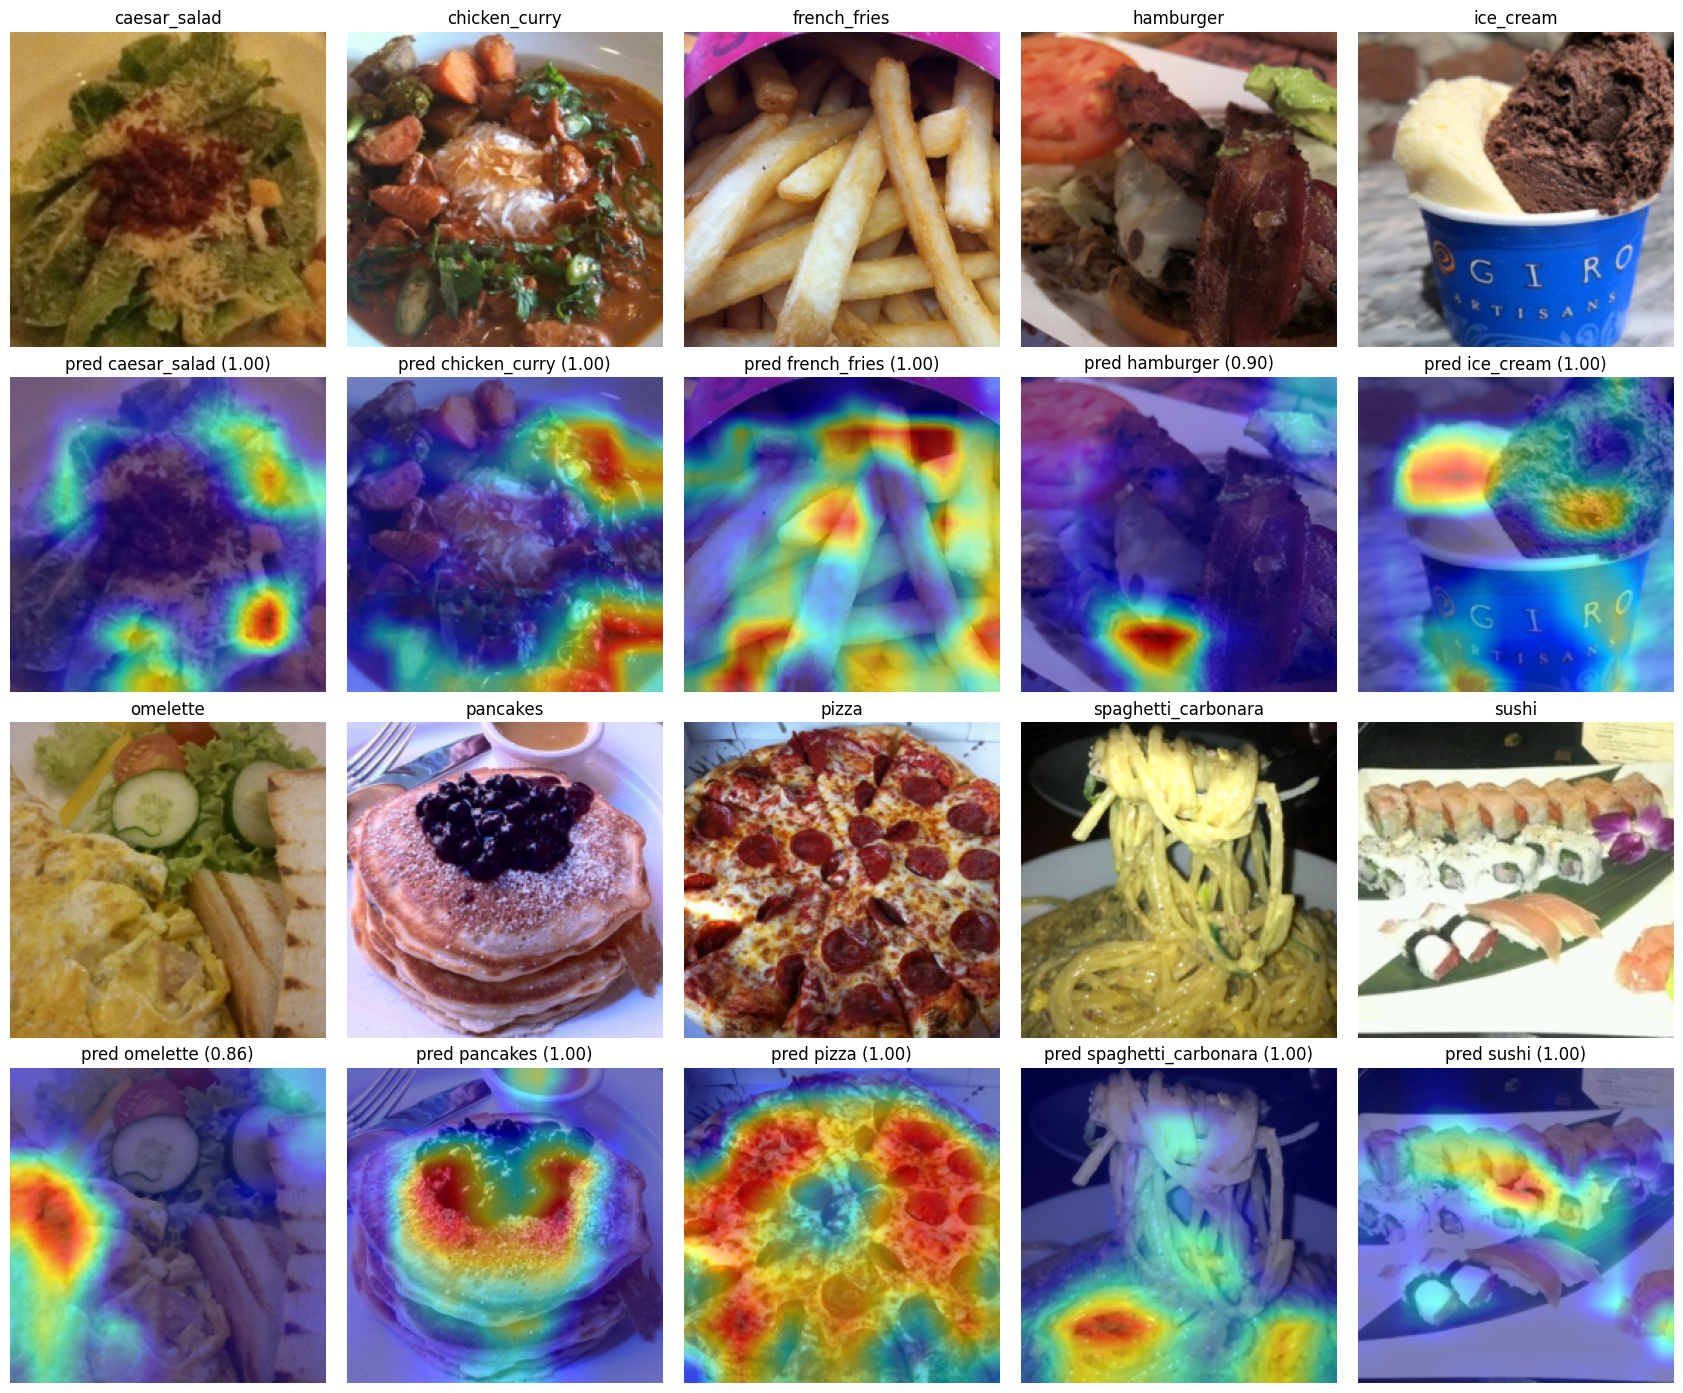

In [ ]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(4, 5, figsize=(17, 14))
for k, c in enumerate(range(len(class_names))):
    i = int(np.where((targets == c) & (preds == c))[0][0])
    o = explainer.explain(Image.open(ds.samples[i][0]))
    r, col = divmod(k, 5)
    axes[2*(r)][col].imshow(o["image"]); axes[2*r][col].set_title(class_names[c]); axes[2*r][col].axis("off")
    axes[2*r+1][col].imshow(o["overlay"])
    axes[2*r+1][col].set_title(f"pred {o['pred']} ({o['confidence']:.2f})"); axes[2*r+1][col].axis("off")
plt.tight_layout(); plt.savefig("results/gradcam_correct.png", dpi=130); plt.show()

number of incorrect answers: 198 / 2500


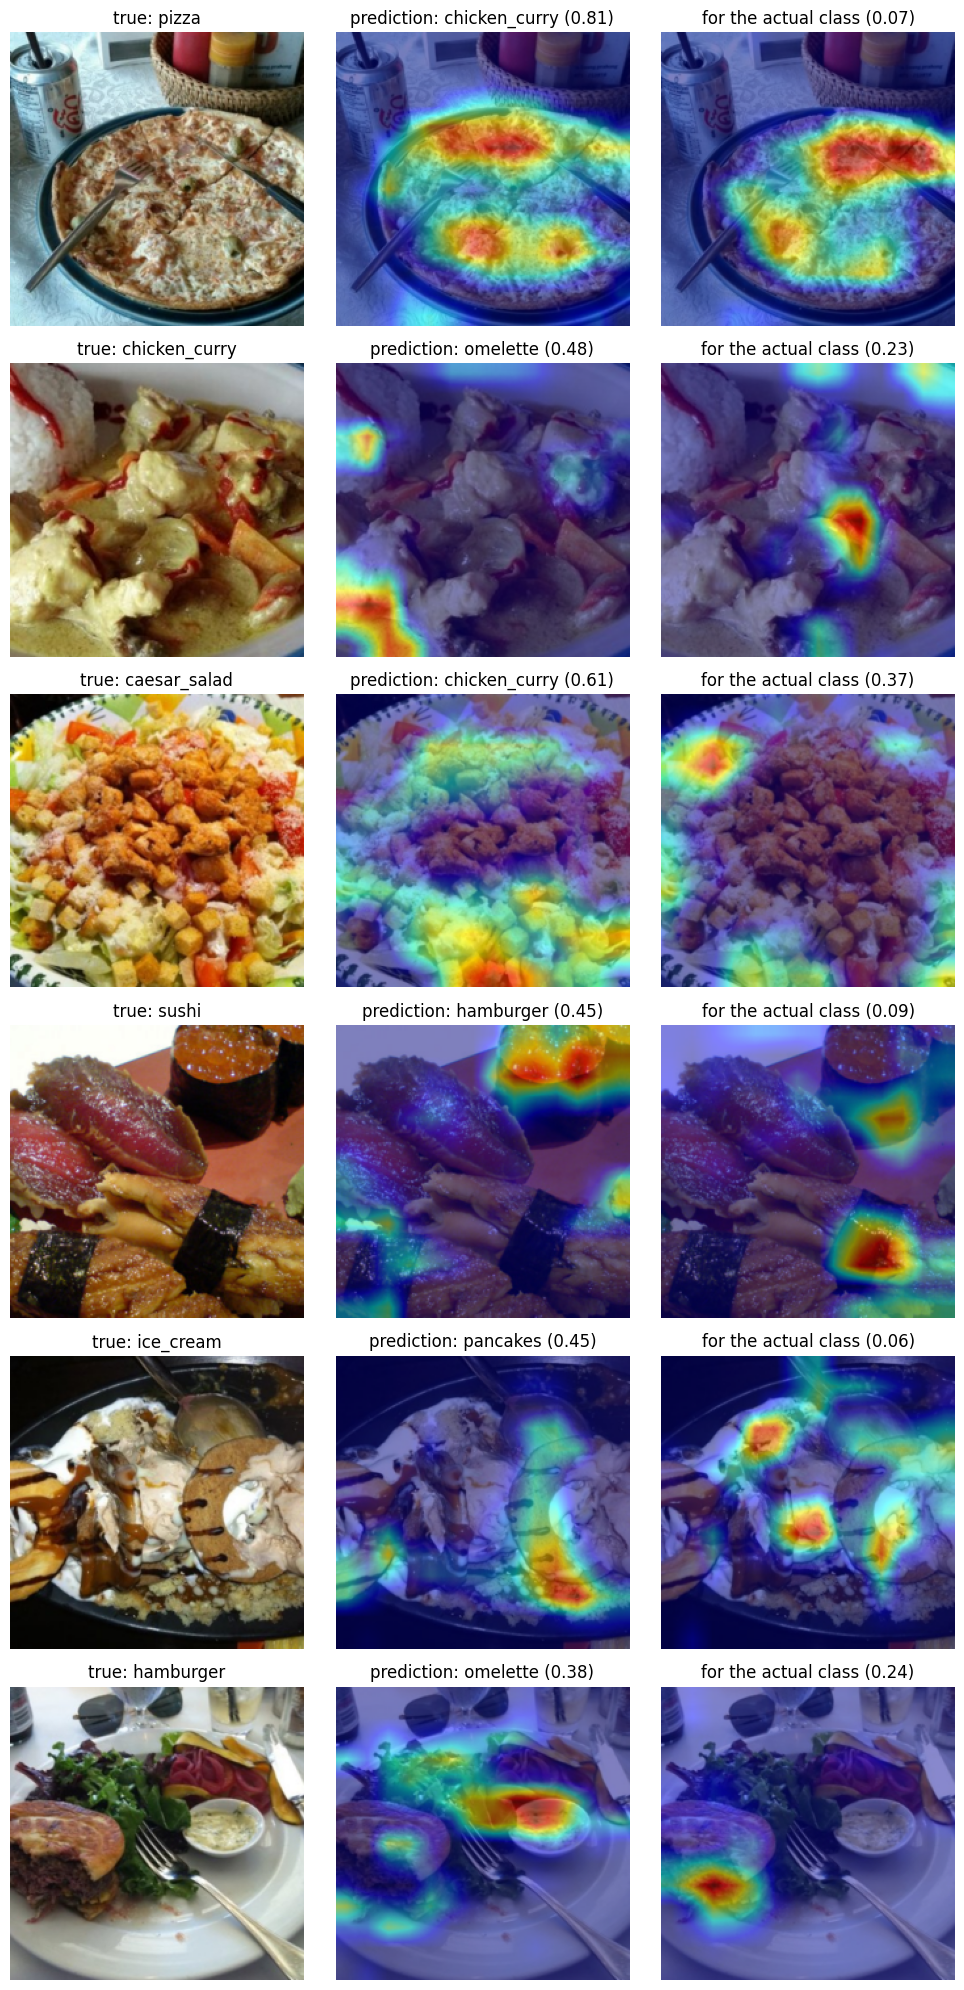

In [ ]:
wrong = np.where(preds != targets)[0]
print("number of incorrect answers:", len(wrong), "/", len(targets))
rng = random.Random(SEED)
pick = rng.sample(list(wrong), 6)

fig, axes = plt.subplots(6, 3, figsize=(10, 20))
for row, i in enumerate(pick):
    img = Image.open(ds.samples[i][0]); true_c = ds.samples[i][1]
    o_pred = explainer.explain(img)                         # predicted class
    o_true = explainer.explain(img, target_class=true_c)    # real class
    axes[row][0].imshow(o_pred["image"]); axes[row][0].set_title(f"true: {class_names[true_c]}")
    axes[row][1].imshow(o_pred["overlay"]); axes[row][1].set_title(f"prediction: {o_pred['pred']} ({o_pred['confidence']:.2f})")
    axes[row][2].imshow(o_true["overlay"]); axes[row][2].set_title(f"for the actual class ({o_true['explained_conf']:.2f})")
    for a in axes[row]: a.axis("off")
plt.tight_layout(); plt.savefig("results/gradcam_errors.png", dpi=130); plt.show()

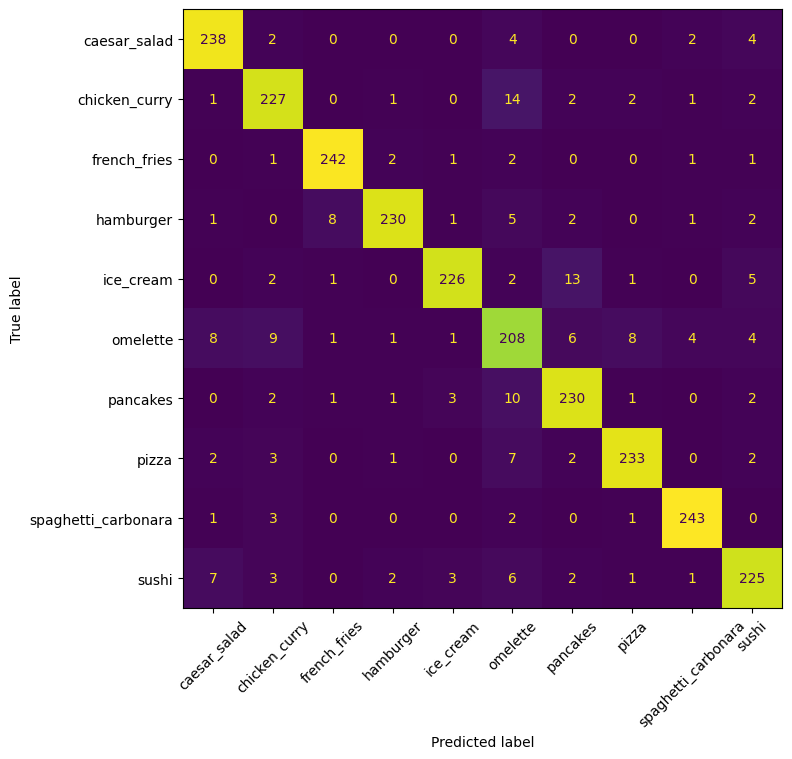

caesar_salad           0.952
chicken_curry          0.908
french_fries           0.968
hamburger              0.920
ice_cream              0.904
omelette               0.832
pancakes               0.920
pizza                  0.932
spaghetti_carbonara    0.972
sushi                  0.900


In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
cm = confusion_matrix(targets, preds)
fig, ax = plt.subplots(figsize=(8, 8))
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(ax=ax, xticks_rotation=45, colorbar=False)
plt.tight_layout(); plt.savefig("results/confusion_matrix.png", dpi=150); plt.show()

for c, n in enumerate(class_names):
    print(f"{n:22s} {cm[c, c] / cm[c].sum():.3f}")

In [ ]:
!cp results/gradcam_correct.png results/gradcam_errors.png results/confusion_matrix.png /content/drive/MyDrive/swe015/